# Credit Card Fraud Detection

### Objective
Build a machine-learning pipeline to identify potentially fraudulent credit-card transactions in a highly imbalanced dataset.

### Project workflow
1. Load and inspect the data
2. Measure class imbalance
3. Explore transaction amounts and the `Time` feature
4. Split data using stratification
5. Train Logistic Regression and Random Forest models
6. Compare Precision, Recall, F1-score and ROC-AUC
7. Inspect feature importance
8. Discuss deployment at high transaction volumes


## 1. Install required libraries
Run this cell if the libraries are not already installed.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)

   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Load the dataset
If the CSV is in a different folder, replace the filename below with its full path.

In [3]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 4. Inspect the dataset

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\\nClass distribution:")
print(df["Class"].value_counts().sort_index())

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 1

## 5. Analyze class imbalance
In this dataset, `Class = 0` means a non-fraudulent transaction and `Class = 1` means a fraudulent transaction.

In [5]:
class_counts = df["Class"].value_counts().sort_index()
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

imbalance_summary = pd.DataFrame({
    "Transaction count": class_counts,
    "Percentage (%)": class_percentages
})
display(imbalance_summary)

fraud_count = int((df["Class"] == 1).sum())
total_count = len(df)
fraud_percentage = fraud_count / total_count * 100

print(f"Total transactions: {total_count:,}")
print(f"Fraudulent transactions: {fraud_count:,}")
print(f"Fraud percentage: {fraud_percentage:.4f}%")

,Transaction count,Percentage (%)
Class,,
0,284315,99.827251
1,492,0.172749


Total transactions: 284,807
Fraudulent transactions: 492
Fraud percentage: 0.1727%


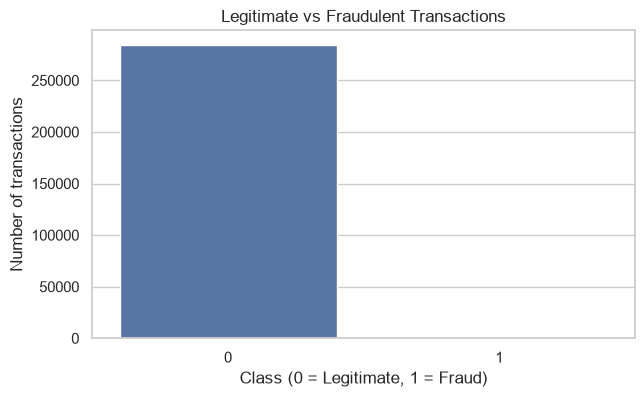

In [6]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of transactions")
plt.show()

### Why accuracy is misleading

Fraud is rare in this dataset. A model that predicts every transaction as legitimate could achieve approximately 99.8% accuracy while detecting **zero** fraudulent transactions. Accuracy alone is therefore not a useful measure of fraud-detection performance.

- **Recall:** What proportion of all fraudulent transactions did the model catch?
- **Precision:** Of the transactions flagged as fraud, what proportion really were fraud?
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures how well the model ranks fraud above legitimate transactions across thresholds.

The preferred balance depends on business costs: missing fraud can be expensive, but too many false alerts also create costs and inconvenience.

## 6. Exploratory Data Analysis (EDA): transaction amounts

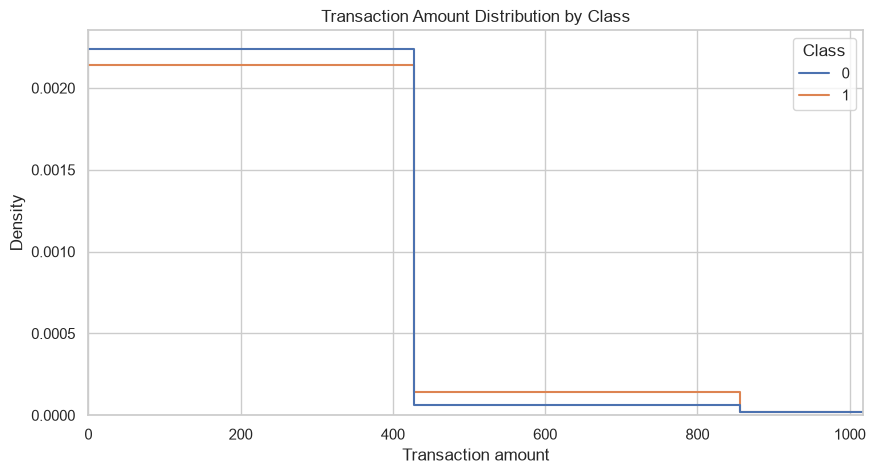

In [7]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction amount")
plt.ylabel("Density")
plt.xlim(0, df["Amount"].quantile(0.99))
plt.show()

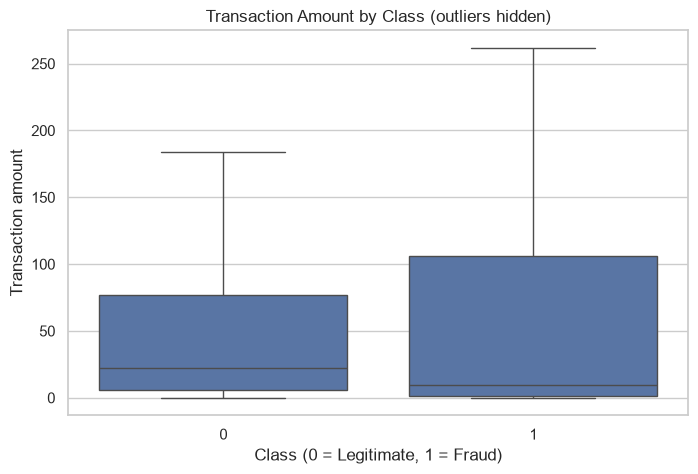

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Class", y="Amount", showfliers=False)
plt.title("Transaction Amount by Class (outliers hidden)")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction amount")
plt.show()

display(df.groupby("Class")["Amount"].describe())

## 7. EDA: time analysis

The `Time` column records elapsed seconds from the first transaction in the dataset. It is **not** a real clock time (such as 9 AM or 8 PM), so these plots show transaction patterns over elapsed time rather than morning/evening activity.

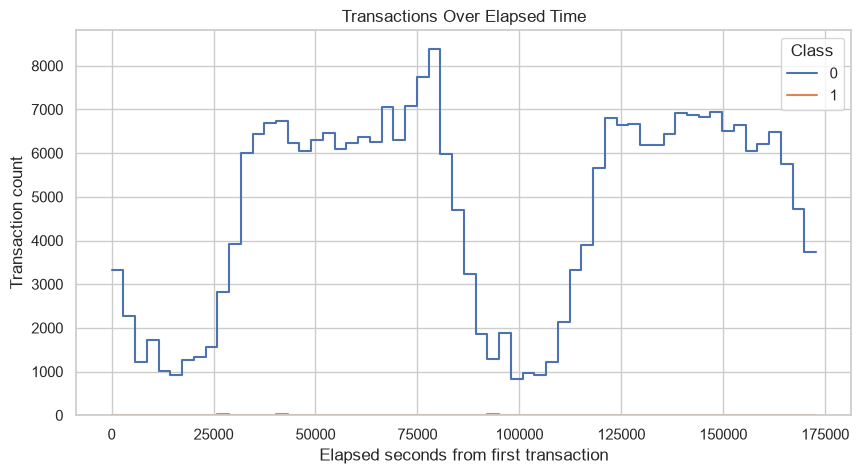

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Time", hue="Class", bins=60, element="step", fill=False)
plt.title("Transactions Over Elapsed Time")
plt.xlabel("Elapsed seconds from first transaction")
plt.ylabel("Transaction count")
plt.show()

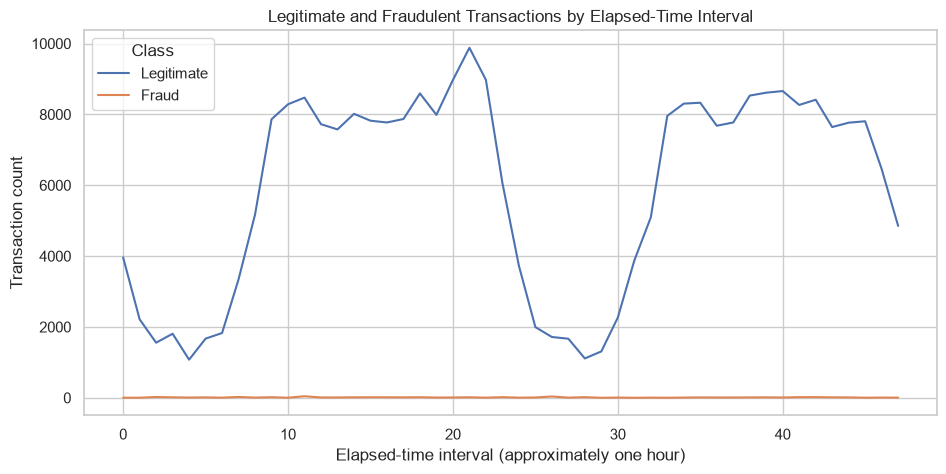

In [10]:
df_time = df.copy()
df_time["Time interval"] = (df_time["Time"] // 3600).astype(int)

hourly_counts = (
    df_time.groupby(["Time interval", "Class"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "Legitimate", 1: "Fraud"})
)

hourly_counts.plot(figsize=(11, 5))
plt.title("Legitimate and Fraudulent Transactions by Elapsed-Time Interval")
plt.xlabel("Elapsed-time interval (approximately one hour)")
plt.ylabel("Transaction count")
plt.show()

## 8. Prepare features and target
`Class` is the target to predict. The remaining columns are input features. We use a stratified split so that the small fraud class is represented in both sets.

In [11]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("\\nFraud percentage in training set:", round(y_train.mean() * 100, 4), "%")
print("Fraud percentage in test set:", round(y_test.mean() * 100, 4), "%")

Training features: (227845, 30)
Test features: (56962, 30)
\nFraud percentage in training set: 0.1729 %
Fraud percentage in test set: 0.172 %


## 9. Train model 1: Logistic Regression with SMOTE

SMOTE creates synthetic minority-class examples. It must be applied **only to the training data**; applying it before the train/test split would leak information into evaluation.

To keep this notebook more practical on ordinary computers, `sampling_strategy=0.1` increases the fraud-to-legitimate ratio to approximately 10% in the resampled training data rather than fully balancing the classes. The test set remains untouched.

In [12]:
logistic_model = ImbPipeline(steps=[
    ("scaler", StandardScaler()),
    ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

Logistic Regression training complete.


## 10. Train model 2: Random Forest with SMOTE
Random Forest can learn non-linear patterns. Training can take longer than Logistic Regression.

In [13]:
random_forest_model = ImbPipeline(steps=[
    ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample"
    ))
])

random_forest_model.fit(X_train, y_train)
print("Random Forest training complete.")

Random Forest training complete.


## 11. Evaluate both models
We report Precision, Recall, F1-score and ROC-AUC. The default classification threshold is used here; threshold tuning can change the precision-recall balance.

In [14]:
logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

results = pd.DataFrame([
    {
        "Model": "Logistic Regression + SMOTE",
        "Precision": precision_score(y_test, logistic_pred, zero_division=0),
        "Recall": recall_score(y_test, logistic_pred, zero_division=0),
        "F1-score": f1_score(y_test, logistic_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, logistic_prob)
    },
    {
        "Model": "Random Forest + SMOTE",
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1-score": f1_score(y_test, rf_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    }
])

display(results.round(4))

,Model,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression + SMOTE,0.3522,0.8878,0.5043,0.9674
1,Random Forest + SMOTE,0.8511,0.8163,0.8333,0.9765


In [15]:
print("Logistic Regression classification report:")
print(classification_report(y_test, logistic_pred, target_names=["Legitimate", "Fraud"], zero_division=0))

print("\\nRandom Forest classification report:")
print(classification_report(y_test, rf_pred, target_names=["Legitimate", "Fraud"], zero_division=0))

Logistic Regression classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.35      0.89      0.50        98

    accuracy                           1.00     56962
   macro avg       0.68      0.94      0.75     56962
weighted avg       1.00      1.00      1.00     56962

\nRandom Forest classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.85      0.82      0.83        98

    accuracy                           1.00     56962
   macro avg       0.93      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



## 12. Confusion matrices
False negatives are fraudulent transactions incorrectly marked legitimate. False positives are legitimate transactions incorrectly flagged as fraud.

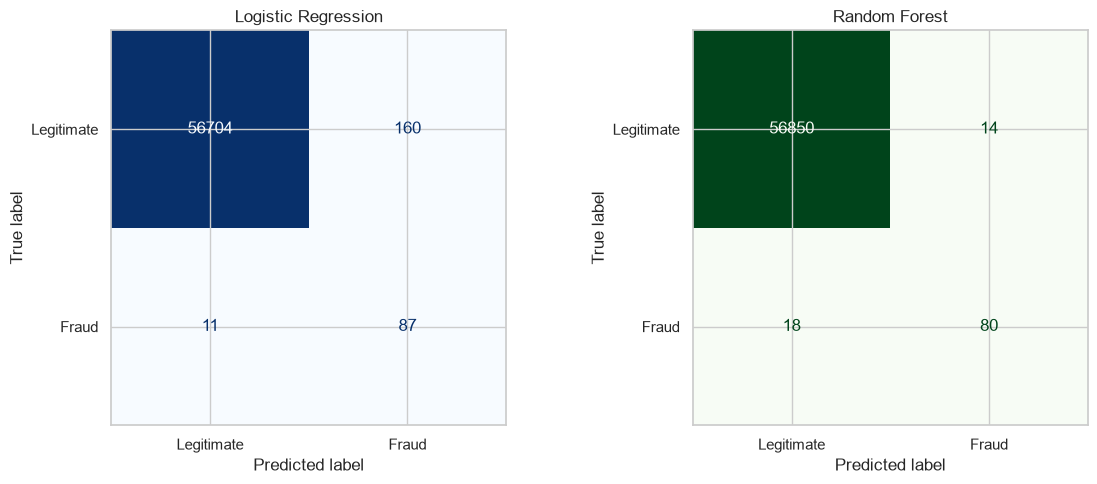

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

## 13. ROC curves

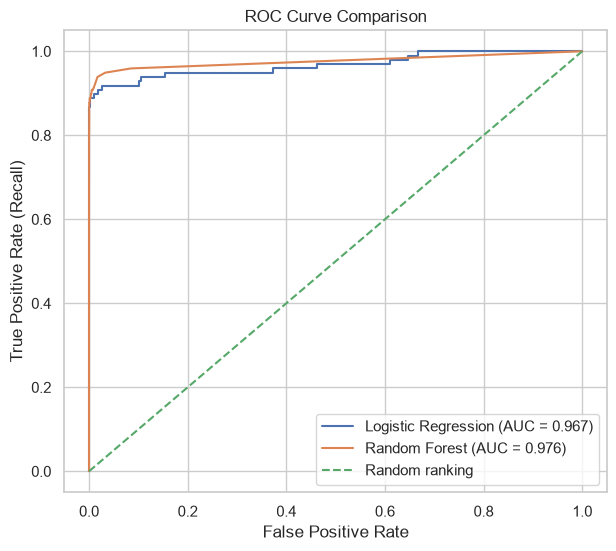

In [17]:
fpr_log, tpr_log, _ = roc_curve(y_test, logistic_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, logistic_prob):.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

## 14. Feature importance
Random Forest feature importance estimates how much each feature contributes to the model's tree splits. It describes model behavior, not causation.

,Feature,Importance
14,V14,0.217473
10,V10,0.121459
4,V4,0.115358
12,V12,0.107800
17,V17,0.085175
3,V3,0.072534
11,V11,0.051477
16,V16,0.040023
2,V2,0.037607
9,V9,0.026629


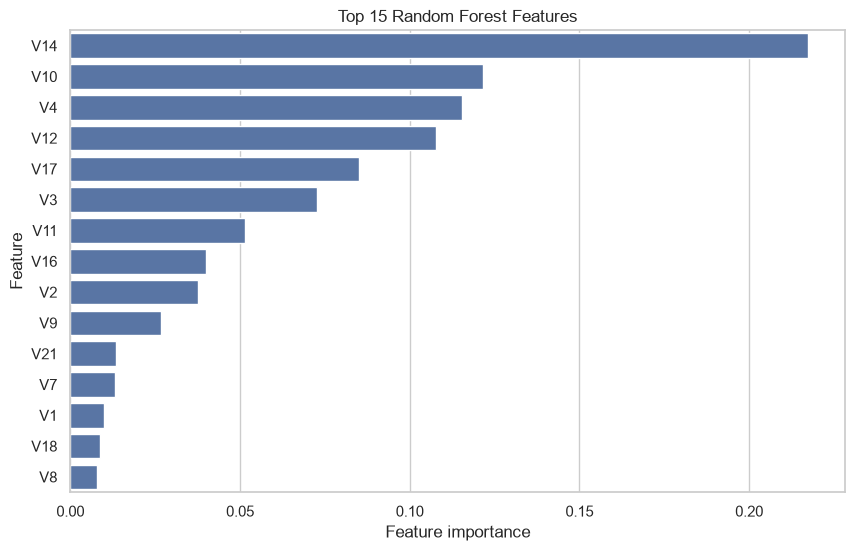

In [18]:
rf_classifier = random_forest_model.named_steps["model"]

importance_df = (
    pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": rf_classifier.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x="Importance", y="Feature")
plt.title("Top 15 Random Forest Features")
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.show()

## 15. Precision vs Recall: interpretation

- **Higher recall** means catching more fraud, but it may flag more legitimate transactions.
- **Higher precision** means fewer false alarms among flagged transactions, but some fraud may be missed.
- In a real payment system, the threshold should be selected using the cost of missed fraud, review capacity, customer friction, and validation data—not simply by choosing the model with the highest accuracy.
- ROC-AUC is useful for ranking quality, but also inspect the precision-recall tradeoff because fraud is rare.

## 16. Scalability: one million transactions per hour

One million transactions per hour is about **278 transactions per second** on average. A production system would need more than a notebook model:

1. **Streaming ingestion:** use a durable event stream such as Kafka or a managed equivalent.
2. **Low-latency inference:** deploy the trained model behind a monitored service and benchmark p95/p99 latency at expected peak traffic.
3. **Online features:** compute required features quickly and consistently between training and serving.
4. **Decision policy:** allow, block, or route uncertain/high-risk transactions to manual review using calibrated thresholds and business rules.
5. **Monitoring:** track latency, error rates, feature drift, fraud recall, precision, false-positive rate, and delayed labels.
6. **Resilience and security:** autoscale, protect sensitive data, log decisions for audit, and define a safe fallback for service failures.

A notebook benchmark is not proof that the model can handle production traffic. Test throughput and latency with realistic load before deployment.

## 17. Project conclusion
Run the models and use the actual metrics from your results table to complete this summary. Do not invent scores.

In [20]:
best_model_row = results.sort_values(["Recall", "F1-score"], ascending=False).iloc[0]

print("Model with highest recall (F1-score breaks ties):", best_model_row["Model"])
print(f"Precision: {best_model_row['Precision']:.4f}")
print(f"Recall:    {best_model_row['Recall']:.4f}")
print(f"F1-score:  {best_model_row['F1-score']:.4f}")
print(f"ROC-AUC:   {best_model_row['ROC-AUC']:.4f}")

Model with highest recall (F1-score breaks ties): Logistic Regression + SMOTE
Precision: 0.3522
Recall:    0.8878
F1-score:  0.5043
ROC-AUC:   0.9674
